# X-Ray Analysis
This is the main analysis program designed by Warith.

Make sure to run each code block in the order they appear, otherwise the program will not work.

## Import the main libraries to be used

In [4]:
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

## Import kagglehub to download the dataset

In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity", output_dir="data")

print("Path to dataset files:", path)

100%|██████████| 204M/204M [00:06<00:00, 30.6MB/s] 

Extracting files...


Path to dataset files: data


## Setting up Matplotlib for visualisation

In [1]:
plt.rc('image', cmap='gray')
plt.rc('figure', autolayout=True)

## Preprocessing
Load the dataset and preprocess it

In [24]:
def preprocess():
    # Define the different paths
    data_dir = Path("data")

    train_dir = data_dir / "train"
    val_dir = data_dir / "val"

    # Loads, resizes and batches images directly from paths

    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        image_size=(224,224),
        batch_size=32,
        shuffle=True,
        color_mode="grayscale"
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        val_dir,
        image_size=(224,224),
        batch_size=32,
        shuffle=True,
        color_mode="grayscale"
    )

    return train_ds, val_ds

## Convolution kernel

Define a convolution kernel
- This makes it possible to extract important image features
- In this case the vital parts of the X-Ray (The bones)

In [11]:
def kernel_sharpening():
    kernel = tf.constant([
        [-1, -1, -1],
        [-1, 9, -1],
        [-1, -1, -1]
    ], dtype=tf.float32, shape=[3, 3, 1, 1])
    return kernel

## Apply Convolution layer to images

Apply the convolution layer by grabbing a batch from the conveyor belt

In [42]:
def apply_kernel(train_ds, kernel):

    for images, labels in train_ds.take(1):
        # convert image tensor to float32
        images_float = tf.cast(images, tf.float32)

        # Apply sharpening kernel
        # strides=[1,1,1,1] moves pixel by pixel
        sharpened_images = tf.nn.conv2d(images_float, kernel, strides=[1,1,1,1], padding="SAME")

        # plots original X-ray vs sharpened feature map side-by-side
        plt.figure(figsize=(10,10))
        # Original
        plt.subplot(1,2,1)
        plt.imshow(images[0].numpy().squeeze(), cmap="gray")
        plt.title("Original X-Ray")
        plt.axis("off")
        # Sharpened
        plt.subplot(1,2,2)
        plt.imshow(sharpened_images[0], cmap="gray")
        plt.title("Sharpened X-Ray")
        plt.axis("off")

        plt.show()
        break

    if sharpened_images is None:
        print("No images found in the dataset")
        return None
    else:
        return sharpened_images

### Calling the functions
The following code block produces an output: that being the original X-Ray and the sharpened X-Ray that can be more easily used for analysis and machine learning

The sharpening kernel is a convolution layer applied to the X-Ray image to extract the vital parts of the X-Ray. This is part of the convolutional neural network used to classify the X-Ray.


Found 5778 files belonging to 5 classes.
Found 826 files belonging to 5 classes.


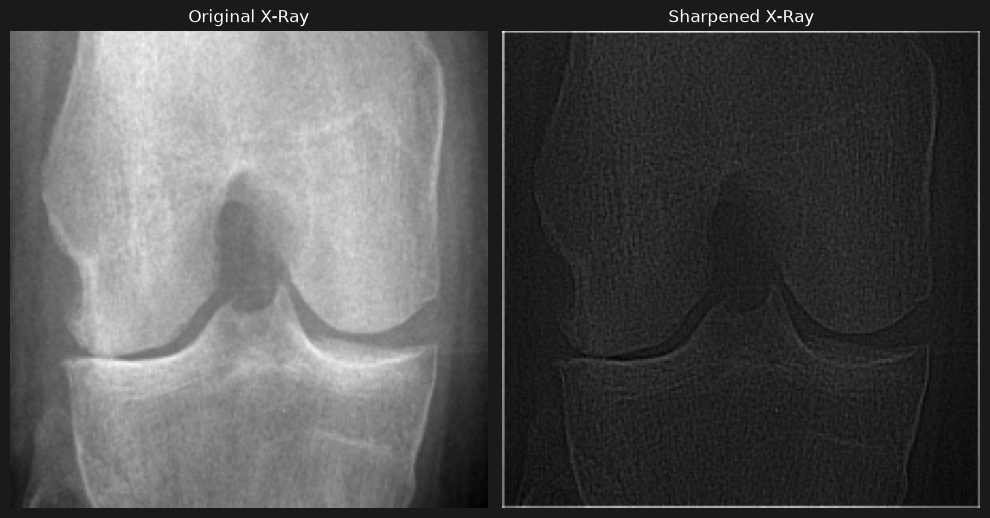

In [47]:
kern = kernel_sharpening()
trainDS, valDS = preprocess()
sharpImage = apply_kernel(trainDS, kern)

## Apply ReLU Activation Function

Removes negative values and introduces non-linearity into the network

In [48]:
def apply_relu(sharpened_images):
    relu_output = tf.nn.relu(sharpened_images)

    print("After ReLU Shape", relu_output.shape)

    plt.figure(figsize=(10,10))
    plt.imshow(tf.squeeze(relu_output[0]), cmap="gray")
    plt.title("After ReLU Activation")
    plt.axis("off")
    return relu_output

## Apply MaxPooling

In [49]:
def apply_max_pooling(relu_output):
    pool_output = tf.nn.max_pool(relu_output, ksize=[1,2,2,1], strides=[1,2,2,1], padding="VALID")

    print("After Max Pooling Shape", pool_output.shape)

    plt.figure(figsize=(10,10))
    plt.imshow(tf.squeeze(pool_output[0]), cmap="gray")
    plt.title("After Max Pooling")
    plt.axis("off")
    return pool_output

## Apply Flatten Layer

In [50]:
def apply_flatten(pool_output):
    flatten_layer = tf.keras.layers.Flatten()
    flatten_output = flatten_layer(pool_output)

    print("After Flattening Shape", flatten_output.shape)
    print("First 20 flattened values")
    print(flatten_output[0:20])
    return flatten_output

## Add Fully Connected Dense Layer

In [51]:
def add_dense_layer(flatten_output):
    dense_layer = tf.keras.layers.Dense(128, activation="relu")
    dense_output = dense_layer(flatten_output)

    return dense_output.shape

After ReLU Shape (32, 224, 224, 1)
After Max Pooling Shape (32, 112, 112, 1)
After Flattening Shape (32, 12544)
First 20 flattened values
tf.Tensor(
[[ 896.  609.  632. ...  416.  401.  603.]
 [ 694.  491.  488. ...  542.  576.  769.]
 [ 657.  459.  463. ...  408.  465.  663.]
 ...
 [1052.  733.  736. ...  338.  330.  461.]
 [ 680.  404.  412. ...  506.  358.  537.]
 [ 350.  251.  267. ...  256.  226.  302.]], shape=(20, 12544), dtype=float32)


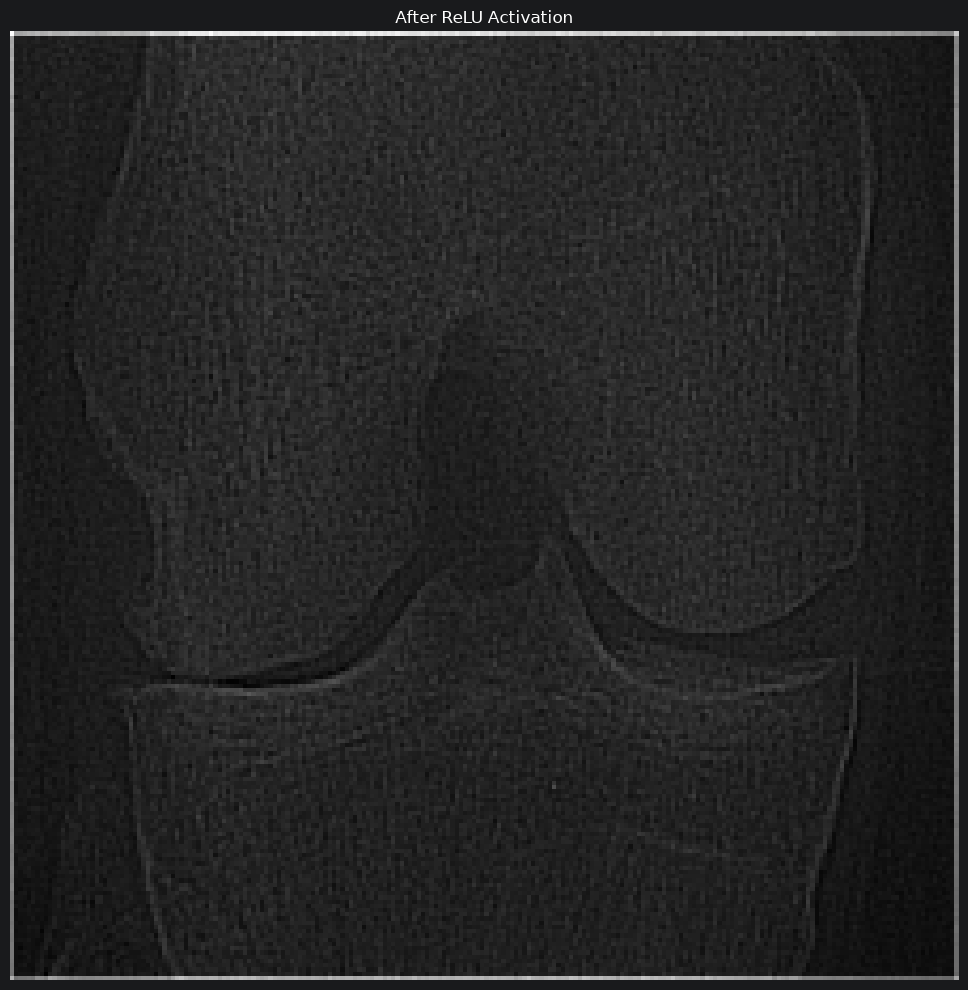

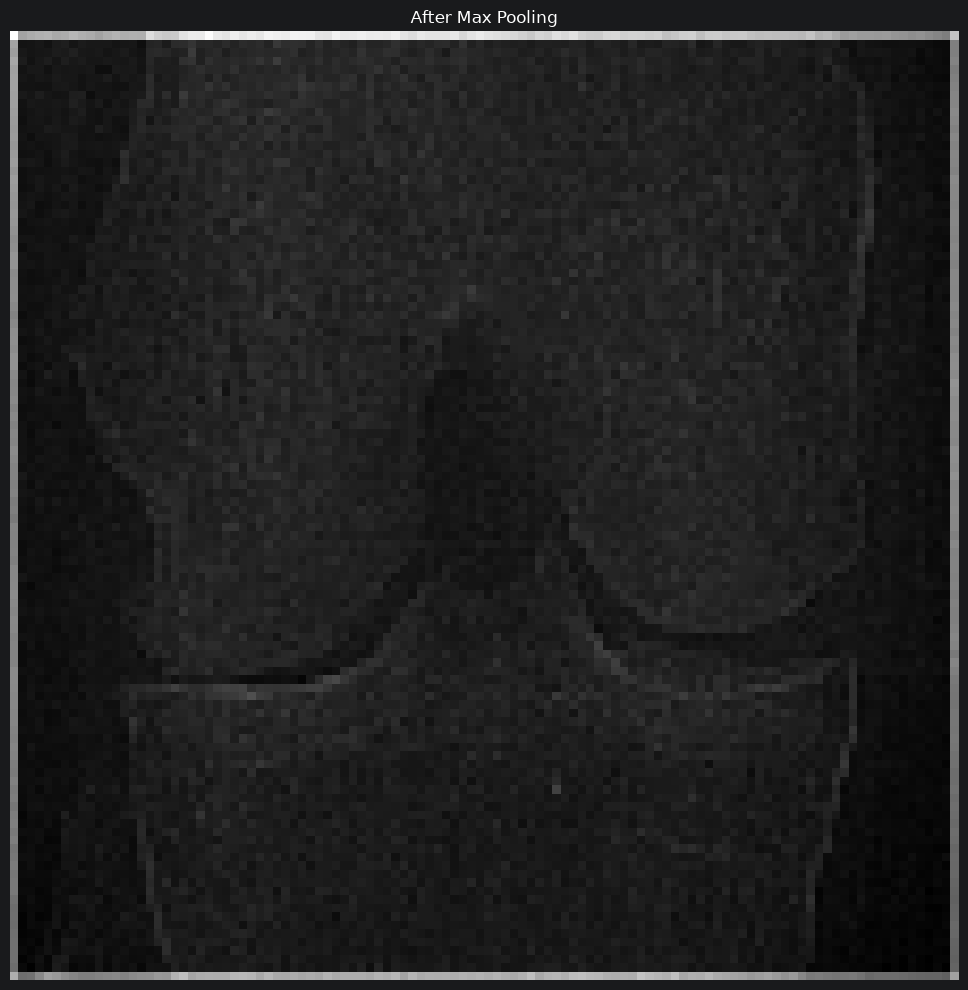

In [52]:
relu = apply_relu(sharpImage)
pool = apply_max_pooling(relu)
flat = apply_flatten(pool)
dense = add_dense_layer(flat)

In [ ]:
from models.arthritis_cnn import load_datasets, build_model, compile_model, train_model, save_model

train_ds, val_ds = load_datasets("data")

tempmodel = build_model()
model = compile_model(tempmodel)

history = train_model(model, train_ds, val_ds, epochs=10)

save_model(model)

Found 5778 files belonging to 5 classes.
Found 826 files belonging to 5 classes.


C:\Users\Warith2\PycharmProjects\-error-404-technical-challenge\.venv\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
C:\Users\Warith2\PycharmProjects\-error-404-technical-challenge\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
181/181 ━━━━━━━━━━━━━━━━━━━━ 138s 743ms/step - accuracy: 0.3866 - loss: 1.4609 - val_accuracy: 0.4031 - val_loss: 1.4142
Epoch 2/10
 10/181 ━━━━━━━━━━━━━━━━━━━━ 2:03 722ms/step - accuracy: 0.4125 - loss: 1.3711